# Pipeline Dataset Coffee Shop Kota Bandung (versi notebook mandiri)

Seluruh kode pipeline ada di notebook ini. Tidak ada `import pipeline`, jadi notebook ini bisa dijalankan sendirian dan sekaligus menjadi dokumentasi metode (lampiran skripsi).

**Struktur:**
- **Bagian A, Konfigurasi.** Parameter yang boleh kamu ubah.
- **Bagian B, Fungsi.** Logika tiap langkah. Kode tersembunyi secara default; klik **⋯** atau tanda panah di sel untuk menampilkannya.
- **Bagian C, Eksekusi.** Menjalankan setiap langkah dan menampilkan hasilnya.

**Cara pakai:**
1. Taruh CSV Open Data di `data/raw/`.
2. Isi `USER_AGENT` dengan email kamu.
3. Klik **Run All**.

Kalau parameter di bagian A diubah, jalankan ulang sel konfigurasi, lalu sel eksekusi yang terdampak.

In [1]:
import json, math, os, re, sys, time, unicodedata
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace

import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from shapely.geometry import Point
from rapidfuzz import fuzz, process
pd.set_option("display.max_colwidth", 60)

## A. Konfigurasi

Semua parameter metodologis ada di sel ini: sumber data, taksonomi kategori, ambang matching, dan presisi geocode.

In [2]:
from pathlib import Path

ROOT = Path.cwd()          # folder tempat notebook ini berada
RAW, INTERIM, FINAL = ROOT / "data/raw", ROOT / "data/interim", ROOT / "data/final"
for d in (RAW, INTERIM, FINAL):
    d.mkdir(parents=True, exist_ok=True)

# ---- Sumber data -----------------------------------------------------------
# CSV Disbudpar Kota Bandung (Open Data Kota Bandung / Satu Data Indonesia),
# diunduh manual lalu ditaruh di data/raw/.
PEMKOT_CSV = RAW / "data_rumah_makan_restoran_cafe_di_kota_bandung.csv"

# Relation OSM batas administrasi Kota Bandung (admin_level=5)
BATAS_OSM_RELATION = 13290062
BATAS_FILE = RAW / "batas_kota_bandung.geojson"
KECAMATAN_FILE = RAW / "kecamatan_kota_bandung.geojson"
KOREKSI_FILE = RAW / "koreksi_koordinat.csv"   # opsional: id_pemkot,lat,lon,catatan

# Sumber POI OSM: "overpass" (unduh langsung) atau path ke file .osm.pbf lokal
OSM_SOURCE = "overpass"
OVERPASS_URL = "https://overpass-api.de/api/interpreter"

USER_AGENT = "skripsi-coffeeshop-bandung (novellina.e@gmail.com)"
CRS_METER = 32748          # UTM zone 48S

# ---- Taksonomi kategori ----------------------------------------------------
#   cafe (induk)
#   ├── coffee shop   syarat: produk utamanya kopi   -> kopi_utama / kopi_hybrid
#   ├── teashop       Chatime, Teazzi, Chagee, ...    -> teashop
#   ├── bubble tea    Mixue, Tianlala, Momoyo, ...    -> bubbletea
#   └── donut/bakery  J.CO, Dunkin'                   -> donut_bakery
#   lainnya: cafe_ambigu (nama hanya "CAFE ..."), non_kopi (resto, bar, shisha, ...)
# Urutan pengecekan di pipeline/kategori.py: brand dulu, baru kata kunci.

# Brand eksplisit (menang atas kata kunci: "J.CO DONUTS & COFFEE" -> donut_bakery)
BRAND_KOPI = (r"STARBUCKS|POINT COFFEE|\bFORE\b|KENANGAN|JANJI JIWA|EXCELSO|TOMORO|TOMORRO|"
              r"\bTUKU\b|\bCALF\b|\bKULO\b|\bZUS\b|KOPI SOE|FLASH COFFEE|KOPI NAKO|KOPI KALCER|"
              r"KOPI DARI HATI|KOPI LAIN HATI|BEAN SPOT|KOPI TOKO DJAWA|ANOMALI")
BRAND_TEASHOP = (r"CHATIME|TEAZZI|CHAGEE|SANCHA|XING FU|GONG CHA|KOI TH|TEGUK|ES TEH|"
                 r"HAUS!?\b|LEMON TEA|THAI TEA")
BRAND_BUBBLETEA = r"TIANLALA|MIXUE|MOMOYO|BOBA|BUBBLE|XI BOBA|MILK TEA"
BRAND_DONUT = r"\bJ\.?\s?CO\b|DUNKIN|KRISPY KREME|DONUT"

# Kata kunci
KOPI = r"COFFEE|COFFE|KOFFIE|KOPI|NGOPI|ESPRESSO|ROASTERY|ROASTER|\bBREW|BARISTA"
CAFE = r"CAFE|KAFE"                      # CAFÉ sudah jadi CAFE setelah normalisasi ASCII
EXCLUDE = r"CAFETARIA|CAFETERIA|KANTIN"
HYBRID = r"RESTO|RESTAURANT|EATERY|KITCHEN|DAPUR|BAKERY|BREAD|ROTI|CAKE|\bTEA\b|\bTEH\b|BISTRO|DINER"
NON_KOPI = (r"RAMEN|SUSHI|UDON|SHABU|YAKINIKU|BAKSO|SATE|AYAM|BEBEK|\bIGA\b|SEAFOOD|GRILL|"
            r"STEAK|SHISHA|SHISA|LOUNGE|\bBAR\b|KARAOKE|CATERING|BILLIARD")

# OSM: tag cuisine -> kategori (cuisine pertama yang dikenali)
OSM_CUISINE_KATEGORI = {"coffee_shop": "kopi_utama", "bubble_tea": "bubbletea", "tea": "teashop",
                        "donut": "donut_bakery", "ice_cream": "non_kopi", "juice": "non_kopi"}

# ---- Matching --------------------------------------------------------------
MATCH_RADIUS_M = 300       # Pemkot (hasil geocode) ke OSM: maksimal jarak
MATCH_NAME_MIN = 85        # skor kemiripan nama (0-100) untuk match spasial
MATCH_NAME_ONLY_MIN = 95   # nama unik tanpa koordinat: harus nyaris identik
DUP_RADIUS_M = 30          # duplikat di dalam OSM (pin + bangunan)

# ---- Dataset final ---------------------------------------------------------
# Kategori yang masuk dataset final. Definisi ketat: hanya kopi_utama.
# Tambah "donut_bakery" kalau J.CO/Dunkin' ingin dihitung sebagai coffee shop.
# "osm_cafe" = objek OSM amenity=cafe yang namanya tidak menunjukkan kategori apa pun
# (setara cafe_ambigu di data Pemkot).
KATEGORI_FINAL = {"kopi_utama", "kopi_hybrid"}
# ---- Geocoding -------------------------------------------------------------
NOMINATIM_URL = "https://nominatim.openstreetmap.org/search"
PHOTON_URL = "https://photon.komoot.io/api/"
GEOCODE_JEDA_DETIK = 1.1          # kebijakan Nominatim: maks 1 request/detik
POI_RADIUS_M = 400                # cari nama coffee shop di sekitar hasil alamat
POI_NAMA_MIN = 80                 # kemiripan nama hasil POI vs nama Pemkot
POI_KOTA_MAX_DARI_ALAMAT_M = 1500 # POI hasil cari se-kota tidak boleh jauh dari alamatnya
# urutan kualitas, terbaik dulu
# Ruas jalan yang pendek: titik tengahnya paling jauh ±setengah panjang ruas dari lokasi asli
JALAN_PENDEK_MAX_M = 300
PRESISI_URUT = ["manual", "poi_dekat_alamat", "poi", "bangunan", "gedung", "jalan_pendek",
                "jalan", "kelurahan", "kecamatan"]
GEOCODE_PRESISI_OK = {"manual", "poi_dekat_alamat", "poi", "bangunan", "gedung", "jalan_pendek"}

# kumpulkan semua konstanta (HURUF BESAR) ke namespace C
C = SimpleNamespace(**{k: v for k, v in dict(globals()).items() if k.isupper()})

## B. Fungsi

### B.1 Normalisasi nama & alamat



In [3]:
import re, unicodedata

GENERIK = {"COFFEE", "COFFE", "KOFFIE", "KOPI", "CAFE", "KAFE", "SHOP", "HOUSE", "AND",
           "THE", "BANDUNG", "BDG", "BY", "CO", "ROASTERY", "ROASTER", "ROASTERS", "KEDAI",
           "SPACE", "BAR", "EATERY", "N", "WARUNG", "WARKOP", "TOKO", "RUMAH"}

def upper_ascii(s) -> str:
    s = unicodedata.normalize("NFKD", str(s or "")).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s.upper()).strip()

def nama_inti(s) -> str:
    """'KOPI KENANGAN - DAGO' -> 'KENANGAN'. Dipakai untuk matching nama."""
    s = upper_ascii(s)
    s = re.split(r"\s[-|(]\s?|\s@\s", s)[0]           # buang suffix cabang
    tok = [t for t in re.split(r"[^A-Z0-9]+", s) if t and t not in GENERIK]
    return " ".join(tok) or re.sub(r"[^A-Z0-9 ]", "", s)

def norm_alamat(a) -> str:
    a = upper_ascii(a).replace(" - ", ", ")
    a = re.split(r"\s?[-,]\s?(?:KEC\.|KECAMATAN|KOTA BANDUNG|KEL\.|KELURAHAN)", a)[0]
    a = re.sub(r"^(JALAN|JLN)\b\.?", "JL.", a)
    a = re.sub(r"\bJL\b\.?\s*", "JL. ", a)
    a = re.sub(r"\bNO\b\s*\.?\s*", "NO.", a)            # "NO. 50" / "NO 50" -> "NO.50"
    m = re.match(r"^(.*?NO\.[\w\-/]+)", a)
    return re.sub(r"\s+", " ", (m.group(1) if m else a).replace(" .", ".")).strip(" ,-")

def norm_jalan(a) -> str:
    """'JL. IR. H. JUANDA NO.21' -> 'IR H JUANDA' (untuk membandingkan nama jalan)."""
    a = upper_ascii(a)
    a = re.sub(r"^(JL|JALAN|JLN)\b\.?\s*", "", a)
    a = re.split(r"\bNO\b", a)[0]
    return " ".join(re.sub(r"[^A-Z0-9 ]", " ", a).split())


GEDUNG = (r"MALL|PLAZA|\bWALK\b|SQUARE|\bITC\b|\bBEC\b|PASKAL|TRANS STUDIO|PARIS VAN JAVA|\bPVJ\b|"
          r"\bBIP\b|CITYLINK|SUMMARECON|HOTEL|APARTEMEN|APARTMENT|TOWER|GEDUNG|GRAHA|RUKO|"
          r"UNIVERSITAS|KAMPUS|STASIUN|BANDARA|\bPASAR\b|MARKET")

def kompak(s) -> str:
    return re.sub(r"[^A-Z0-9]", "", upper_ascii(s))

def parse_alamat(a) -> dict:
    """Pecah alamat Pemkot jadi komponen. Format 2022-2023:
    'JL. X NO.1, KELURAHAN, KEC. Y, KOTA BANDUNG, JAWA BARAT 40xxx'."""
    a = upper_ascii(a)
    kodepos = (re.search(r"\b(40\d{3})\b", a) or [None, ""])[1]
    seg = [t.strip(" .") for t in re.split(r",|\s-\s", a) if t.strip(" .")]
    kec = kel = gedung = ""
    jalan = next((t for t in seg if re.match(r"^(JL|JALAN|JLN|GG|GANG|KOMP|KOMPLEK|PERUM)\b", t)), "")
    for i, t in enumerate(seg):
        m = re.match(r"^(?:KEC|KECAMATAN)\b\.?\s*(.+)$", t)
        if m:
            kec = m.group(1).strip()
            if i > 0 and seg[i-1] != jalan and not re.search(r"\bNO\b|\d", seg[i-1]):
                kel = re.sub(r"^(?:KEL|KELURAHAN)\b\.?\s*", "", seg[i-1])
    for t in seg:
        if t != jalan and re.search(GEDUNG, t) and not re.match(r"^(KEC|KOTA|JAWA)", t):
            g, prev = t, None
            while g != prev:                       # buang "LT. 2", "UNIT 5", "GF" di depan
                prev = g
                g = re.sub(r"^(GF|LG|UG|LT\.?\s*\w+|LANTAI\s*\w+|UNIT\s*\S+|BLOK\s*\S+|NO\.?\s*\S+)\s*", "", g)
            gedung = g; break
    if not jalan:
        jalan = norm_alamat(a)
    return {"jalan": jalan, "kelurahan": kel, "kecamatan": kec, "kodepos": kodepos, "gedung": gedung}

def jalan_query(j) -> str:
    """'JL. IR. H. JUANDA NO.21' -> 'Jalan Ir. H. Juanda 21' (lebih dikenali Nominatim/Photon)."""
    j = re.sub(r"^(JL|JLN)\b\.?\s*", "JALAN ", upper_ascii(j))
    j = re.sub(r"^GG\b\.?\s*", "GANG ", j)
    j = re.sub(r"^(.*?\bNO\b\.?\s*[0-9][\w\-/]*).*$", r"\1", j)   # buang sisa setelah nomor
    j = re.sub(r"\bNO\b\.?\s*", "", j)
    j = re.sub(r"(\d+)\s*[-/]\s*\d+\w*", r"\1", j)     # "131-139" -> "131"
    return re.sub(r"\s+", " ", j).strip().title()


def keluarga(inti) -> str:
    """Kunci 'keluarga' nama: token pertama nama inti ('372 DAGO PAKAR' -> '372').
    Dipakai mendeteksi rantai/cabang yang penamaannya tidak seragam."""
    t = str(inti or "").split()
    return t[0] if t and (len(t[0]) >= 3 or t[0].isdigit()) else str(inti or "")

def tandai_rantai(nama_inti_series, jalan_series):
    """True untuk nama yang 'keluarga'-nya muncul di lebih dari satu jalan berbeda."""
    import pandas as pd
    df = pd.DataFrame({"k": nama_inti_series.map(keluarga), "j": jalan_series.map(norm_jalan)})
    n = df.groupby("k").j.nunique()
    return df.k.map(n).fillna(1) > 1

util = SimpleNamespace(**{n: globals()[n] for n in ['upper_ascii', 'nama_inti', 'norm_alamat', 'norm_jalan', 'kompak', 'parse_alamat', 'jalan_query', 'keluarga', 'tandai_rantai']})

### B.2 Klasifikasi kategori (taksonomi)

```
Satu-satunya tempat aturan kategori. Dipakai untuk data Pemkot (nama) dan OSM (nama + cuisine).
```

In [4]:
import re

def dari_nama(nama) -> str:
    n = upper_ascii(nama)
    # 1. brand eksplisit
    if re.search(C.BRAND_DONUT, n):
        return "donut_bakery"
    if re.search(C.BRAND_BUBBLETEA, n):
        return "bubbletea"
    if re.search(C.BRAND_TEASHOP, n):
        return "teashop"
    if re.search(C.BRAND_KOPI, n):
        return "kopi_utama"
    # 2. kata kunci
    kopi = re.search(C.KOPI, n) is not None
    if re.search(C.NON_KOPI, n) and not kopi:
        return "non_kopi"
    if kopi and (re.search(C.HYBRID, n) or re.search(C.NON_KOPI, n)):
        return "kopi_hybrid"         # kopi + makanan/bar ("GRILL, PIZZA & COFFEE")
    if kopi:
        return "kopi_utama"
    if re.search(C.HYBRID, n):
        return "non_kopi"            # "CAFE & RESTO" tanpa kata kopi
    if re.search(C.CAFE, n):
        return "cafe_ambigu"
    return "lainnya"                 # tidak ada petunjuk sama sekali

def relevan(nama) -> bool:
    """Apakah baris Pemkot perlu diambil (punya kata kunci cafe/kopi ATAU brand dalam taksonomi)."""
    n = upper_ascii(nama)
    if re.search(C.EXCLUDE, n):
        return False
    pola = "|".join([C.KOPI, C.CAFE, C.BRAND_KOPI, C.BRAND_TEASHOP, C.BRAND_BUBBLETEA, C.BRAND_DONUT])
    return re.search(pola, n) is not None

def dari_osm(nama, cuisine) -> str:
    k = dari_nama(nama)
    if k in {"donut_bakery", "bubbletea", "teashop", "kopi_utama", "kopi_hybrid"}:
        return k                     # brand / kata kunci kopi di nama paling dapat dipercaya
    for c in str(cuisine or "").split(";"):
        if c.strip() in C.OSM_CUISINE_KATEGORI:
            return C.OSM_CUISINE_KATEGORI[c.strip()]
    if k == "non_kopi":
        return k
    return "osm_cafe"                # amenity=cafe tanpa petunjuk lain

K = SimpleNamespace(**{n: globals()[n] for n in ['dari_nama', 'relevan', 'dari_osm']})

### B.3 Langkah 1: batas kota & kecamatan

```
Langkah 1: batas administrasi Kota Bandung dari OSM (relation, bukan bbox).
```

In [5]:
import geopandas as gpd

def run():
    import osmnx as ox
    ox.settings.http_user_agent = C.USER_AGENT
    gdf = ox.geocode_to_gdf(f"R{C.BATAS_OSM_RELATION}", by_osmid=True)
    gdf[["geometry"]].assign(nama="Kota Bandung").to_file(C.BATAS_FILE, driver="GeoJSON")
    kec = ox.features_from_polygon(gdf.geometry.iat[0],
                                   {"boundary": "administrative", "admin_level": "6"})
    kec = kec.reset_index()
    # osmnx menggabungkan tag dengan OR, jadi kelurahan (admin_level=7) dll. ikut terambil.
    # Saring lagi: hanya relation admin_level=6 (kecamatan) yang benar-benar di dalam kota.
    kec = kec[(kec["admin_level"].astype(str) == "6")
              & (kec["boundary"] == "administrative")
              & kec.geom_type.isin(["Polygon", "MultiPolygon"])]
    kec = kec[kec.representative_point().within(gdf.geometry.iat[0])]
    kec = kec.drop_duplicates("name")
    kec[["name", "geometry"]].rename(columns={"name": "kecamatan"}).to_file(C.KECAMATAN_FILE, driver="GeoJSON")
    print(f"[1] {len(kec)} kecamatan -> {C.KECAMATAN_FILE.name}")
    if len(kec) != 30:
        print(f"    PERINGATAN: Kota Bandung punya 30 kecamatan, didapat {len(kec)}: {sorted(kec.name)}")
    luas = gdf.to_crs(C.CRS_METER).area.iat[0] / 1e6
    print(f"[1] batas Kota Bandung: {luas:.1f} km² -> {C.BATAS_FILE.name}")

def load():
    if not C.BATAS_FILE.exists():
        raise SystemExit("Batas kota belum ada. Jalankan: python run.py batas")
    return gpd.read_file(C.BATAS_FILE).to_crs(4326)


def load_kecamatan():
    if not C.KECAMATAN_FILE.exists():
        return None
    k = gpd.read_file(C.KECAMATAN_FILE).to_crs(4326)
    k["kunci"] = k.kecamatan.map(kompak)
    return k

s1_batas = SimpleNamespace(**{n: globals()[n] for n in ['run', 'load', 'load_kecamatan']})

### B.4 Langkah 2: POI OpenStreetMap

```
Langkah 2: POI coffee shop dari OSM (Overpass atau file .osm.pbf lokal).
```

In [6]:
import json, re
from datetime import datetime, timezone
import pandas as pd, geopandas as gpd
from shapely.geometry import Point

OUT_S2 = C.INTERIM / "osm_cafe.geojson"
TAGS = ["name", "brand", "cuisine", "opening_hours", "addr:street", "addr:housenumber"]

def is_coffee(t):
    return t.get("amenity") == "cafe" or t.get("cuisine", "").split(";")[0] == "coffee_shop"

def rec(tipe, oid, tags, lon, lat):
    r = {"osm_type": tipe, "osm_id": oid, "geometry": Point(lon, lat)}
    r.update({k.replace("addr:", "addr_"): tags.get(k, "") for k in TAGS})
    r["semua_tag"] = json.dumps(dict(tags), ensure_ascii=False)
    return r

def from_overpass(batas):
    import requests
    minx, miny, maxx, maxy = batas.total_bounds
    bb = f"{miny-0.01},{minx-0.01},{maxy+0.01},{maxx+0.01}"
    q = f"""[out:json][timeout:180];
    ( nwr["amenity"="cafe"]({bb}); nwr["cuisine"~"^coffee_shop"]({bb}); );
    out center tags;"""
    r = requests.post(C.OVERPASS_URL, data={"data": q},
                      headers={"User-Agent": C.USER_AGENT}, timeout=300)
    r.raise_for_status()
    js = r.json()
    rows = []
    for e in js["elements"]:
        t = e.get("tags", {})
        if not is_coffee(t):
            continue
        lon, lat = (e["lon"], e["lat"]) if e["type"] == "node" else \
                   (e["center"]["lon"], e["center"]["lat"])
        rows.append(rec(e["type"], e["id"], t, lon, lat))
    return rows, js["osm3s"]["timestamp_osm_base"]

def from_pbf(path):
    import osmium
    from shapely import wkb
    fac, rows = osmium.geom.WKBFactory(), []
    class H(osmium.SimpleHandler):
        def node(self, n):
            if is_coffee(n.tags):
                rows.append(rec("node", n.id, n.tags, n.location.lon, n.location.lat))
        def area(self, a):
            if not is_coffee(a.tags):
                return
            try:
                g = gpd.GeoSeries([wkb.loads(fac.create_multipolygon(a), hex=True)], crs=4326)
            except Exception:
                return
            c = g.to_crs(C.CRS_METER).centroid.to_crs(4326).iat[0]
            rows.append(rec("way" if a.from_way() else "relation", a.orig_id(), a.tags, c.x, c.y))
    H().apply_file(str(path), locations=True)
    hdr = osmium.io.Reader(str(path), osmium.osm.osm_entity_bits.NOTHING).header()
    return rows, hdr.get("osmosis_replication_timestamp") or "tidak diketahui"

def run(source=None):
    source = source or C.OSM_SOURCE
    batas = s1_batas.load()
    rows, snap = from_overpass(batas) if source == "overpass" else from_pbf(source)
    gdf = gpd.GeoDataFrame(rows, crs=4326)
    n0 = len(gdf)
    gdf = gdf[gdf.within(batas.union_all())].copy()
    gdf["osm_key"] = gdf.osm_type + "/" + gdf.osm_id.astype(str)
    gdf["nama_inti"] = gdf["name"].map(nama_inti)
    gdf["kategori_osm"] = [K.dari_osm(n, c) for n, c in zip(gdf["name"], gdf["cuisine"])]
    gdf["flag_non_kopi"] = ~gdf.kategori_osm.isin(["kopi_utama", "kopi_hybrid", "osm_cafe"])

    # duplikat internal OSM: nama inti sama & < DUP_RADIUS_M. Simpan node, buang yang lain
    m = gdf.to_crs(C.CRS_METER)
    named = m[m.nama_inti != ""]
    p = gpd.sjoin_nearest(named, named, max_distance=C.DUP_RADIUS_M, exclusive=True)
    p = p[p.nama_inti_left == p.nama_inti_right]
    gdf["dup_dengan"] = ""
    for idx, r in p.iterrows():
        gdf.at[idx, "dup_dengan"] = r.osm_key_right
    rank = gdf.osm_type.map({"node": 0, "way": 1, "relation": 2})
    gdf["dup_dibuang"] = False
    seen = set()
    for idx in rank.sort_values().index:
        k, d = gdf.at[idx, "osm_key"], gdf.at[idx, "dup_dengan"]
        if d and d in seen:
            gdf.at[idx, "dup_dibuang"] = True
        seen.add(k)

    gdf["snapshot_osm"] = str(snap) + " "   # spasi: cegah GeoJSON mengubahnya jadi datetime
    gdf.to_file(OUT_S2, driver="GeoJSON")
    print(f"[2] OSM ({source}): {n0} objek, {len(gdf)} di dalam Kota Bandung, "
          f"{gdf.dup_dibuang.sum()} duplikat. snapshot {snap}")
    print(f"    kategori: {gdf[~gdf.dup_dibuang].kategori_osm.value_counts().to_dict()}")

def load():
    gdf = gpd.read_file(OUT_S2)
    gdf["snapshot_osm"] = gdf.snapshot_osm.astype(str).str.strip()   # GeoJSON suka mengubahnya jadi datetime
    for c in ("name", "brand", "cuisine", "addr_street", "addr_housenumber", "dup_dengan"):
        gdf[c] = gdf[c].fillna("")
    return gdf

s2_osm = SimpleNamespace(**{n: globals()[n] for n in ['is_coffee', 'rec', 'from_overpass', 'from_pbf', 'run', 'load']})

### B.5 Langkah 3: data Open Data Pemkot

```
Langkah 3: bersihkan & klasifikasikan data Disbudpar Kota Bandung.
```

In [7]:
import re
import pandas as pd

OUT_S3 = C.INTERIM / "pemkot_cafe.csv"

def run():
    df = pd.read_csv(C.PEMKOT_CSV)
    n_raw = len(df)
    df["nama"] = df.nama_rumah_makan.map(upper_ascii)
    df = df[df.nama.map(K.relevan)].copy()
    df["alamat_norm"] = df.alamat.map(norm_alamat)
    df["_len"] = df.alamat.str.len()
    lengkap = (df.sort_values("_len").groupby(["nama", "alamat_norm"]).alamat.last()
                 .rename("alamat_lengkap"))          # versi alamat dengan info terbanyak
    df = (df.sort_values("tahun")
            .groupby(["nama", "alamat_norm"], as_index=False)
            .agg(tahun_pertama=("tahun", "min"), tahun_terakhir=("tahun", "max"),
                 n_tahun=("tahun", "nunique"), alamat_asli=("alamat", "last"),
                 id_pemkot=("id", "first")))
    df = df.merge(lengkap, on=["nama", "alamat_norm"])
    for c in ("alamat_asli", "alamat_lengkap"):
        df[c] = df[c].str.replace(r"\s+", " ", regex=True)
    df = df.join(pd.DataFrame(df.alamat_lengkap.map(parse_alamat).tolist(), index=df.index))
    df["kategori"] = df.nama.map(K.dari_nama)
    df["nama_inti"] = df.nama.map(nama_inti)
    df.to_csv(OUT_S3, index=False)
    print(f"[3] Pemkot: {n_raw} baris mentah -> {len(df)} tempat unik "
          f"({df.kategori.value_counts().to_dict()})")

def load():
    return pd.read_csv(OUT_S3, keep_default_na=False)

s3_pemkot = SimpleNamespace(**{n: globals()[n] for n in ['run', 'load']})

### B.6 Langkah 4: geocoding berjenjang

```
Langkah 4: koordinat untuk data Pemkot (yang tidak punya lat/lon).

Strategi berjenjang per tempat, semua berbasis data OSM (legal & gratis):

  0. koreksi manual          data/raw/koreksi_koordinat.csv (selalu menang)
  1. alamat                  Nominatim, lalu Photon      -> presisi 'bangunan' / 'jalan'
  2. nama di sekitar alamat  cari nama coffee shop dalam radius POI_RADIUS_M dari hasil 1
                                                         -> 'poi_dekat_alamat' (paling meyakinkan)
  3. nama se-kota            hanya untuk nama yang BUKAN rantai -> 'poi'
  4. gedung/mall             "PARIS VAN JAVA", "ISTANA PLAZA" -> 'gedung'
  5. kelurahan / kecamatan   titik tengah wilayah (hanya cadangan, tidak masuk final)

Setiap kandidat divalidasi: harus di dalam Kota Bandung, dan kalau alamat menyebut
kecamatan, titiknya harus jatuh di kecamatan itu. Semua request di-cache, jadi
proses bisa dihentikan (Ctrl+C) dan dilanjutkan kapan saja.
```

In [8]:
import json, math, time
import pandas as pd
from shapely.geometry import Point
from rapidfuzz import fuzz

CACHE_S4 = C.INTERIM / "geocode_cache.json"
OUT_S4 = C.INTERIM / "pemkot_geocoded.csv"
RANK = {p: i for i, p in enumerate(C.PRESISI_URUT)}
POI_CLASS = {"amenity", "shop", "tourism", "leisure"}
KOLOM = ["geo_lat", "geo_lon", "geo_presisi", "geo_metode", "geo_label", "geo_skor_nama",
         "geo_n_kandidat", "geo_selisih_m", "geo_ditolak", "geo_ketidakpastian_m"]


# --------------------------------------------------------------------------- HTTP
class Geocoder:
    def __init__(self, bbox):
        import requests
        self.s = requests.Session()
        self.s.headers["User-Agent"] = C.USER_AGENT
        self.bbox = bbox                                   # minx, miny, maxx, maxy
        self.cache = json.loads(CACHE_S4.read_text()) if CACHE_S4.exists() else {}
        self.n_baru = 0
        self.gagal_beruntun = 0

    def simpan(self):
        CACHE_S4.write_text(json.dumps(self.cache, ensure_ascii=False))

    def _get(self, url, params, key):
        if key in self.cache:
            return self.cache[key]
        if self.gagal_beruntun >= 5:
            raise RuntimeError("5x gagal berturut-turut: cek internet atau rate limit")
        time.sleep(C.GEOCODE_JEDA_DETIK)
        try:
            r = self.s.get(url, params=params, timeout=20)
            r.raise_for_status()
            js = r.json()
            self.gagal_beruntun = 0
        except Exception as e:
            self.gagal_beruntun += 1
            print(f"   ! {type(e).__name__} untuk {key[:70]}")
            return None                                    # tidak di-cache, dicoba lagi lain kali
        self.cache[key] = js
        self.n_baru += 1
        if self.n_baru % 25 == 0:
            self.simpan()
        return js

    def nominatim(self, q, box=None):
        minx, miny, maxx, maxy = box or self.bbox
        p = {"q": q, "format": "jsonv2", "limit": 5, "countrycodes": "id",
             "viewbox": f"{minx},{maxy},{maxx},{miny}", "bounded": 1}
        js = self._get(C.NOMINATIM_URL, p, f"N|{q}|{box}") or []
        out = []
        for h in js:
            bb = h.get("boundingbox")            # [minlat, maxlat, minlon, maxlon]
            ext = [float(bb[2]), float(bb[0]), float(bb[3]), float(bb[1])] if bb else None
            out.append(dict(lat=float(h["lat"]), lon=float(h["lon"]),
                            cls=h.get("category", h.get("class", "")), typ=h.get("type", ""),
                            addrtype=h.get("addresstype", ""), name=h.get("name", ""),
                            label=h.get("display_name", ""), src="nominatim", extent=ext))
        return out

    def photon(self, q, box=None):
        minx, miny, maxx, maxy = box or self.bbox
        p = {"q": q, "limit": 5, "bbox": f"{minx},{miny},{maxx},{maxy}"}
        js = self._get(C.PHOTON_URL, p, f"P|{q}|{box}") or {}
        out = []
        for f in js.get("features", []):
            pr, (lon, lat) = f["properties"], f["geometry"]["coordinates"]
            out.append(dict(lat=lat, lon=lon, cls=pr.get("osm_key", ""), typ=pr.get("osm_value", ""),
                            addrtype=pr.get("type", ""), name=pr.get("name", ""),
                            label=", ".join(str(pr[k]) for k in ("name", "street", "housenumber",
                                                                 "district") if pr.get(k)),
                            src="photon", housenumber=pr.get("housenumber", ""),
                            extent=pr.get("extent")))   # [minlon, maxlat, maxlon, minlat]
        return out


# --------------------------------------------------------------------------- helper
def jarak_m(a, b):
    la1, lo1, la2, lo2 = map(math.radians, (a[0], a[1], b[0], b[1]))
    h = math.sin((la2-la1)/2)**2 + math.cos(la1)*math.cos(la2)*math.sin((lo2-lo1)/2)**2
    return 2 * 6371000 * math.asin(math.sqrt(h))

def box_sekitar(lat, lon, r_m):
    dlat = r_m / 111_320
    dlon = r_m / (111_320 * math.cos(math.radians(lat)))
    return (lon - dlon, lat - dlat, lon + dlon, lat + dlat)

def setengah_diagonal_m(h):
    """Ketidakpastian kasar: setengah diagonal bounding box hasil (meter)."""
    e = h.get("extent")
    if not e:
        return None
    x1, y1, x2, y2 = map(float, e)
    return round(jarak_m((y1, x1), (y2, x2)) / 2, 1)

def presisi_alamat(h, punya_nomor):
    if (h["cls"] in {"building", "place"} and h["typ"] in {"house", "yes", "building"}) \
       or h["addrtype"] in {"building", "house"} or (h.get("housenumber") and punya_nomor):
        return "bangunan"
    if h["cls"] == "highway" or h["addrtype"] in {"road", "street"}:
        d = setengah_diagonal_m(h)
        return "jalan_pendek" if d is not None and d * 2 <= C.JALAN_PENDEK_MAX_M else "jalan"
    if h["cls"] in POI_CLASS:
        return "bangunan"                 # alamat jatuh tepat di sebuah POI
    return None

def cocok_nama(h, inti):
    if h["cls"] not in POI_CLASS or not h["name"]:
        return 0
    return fuzz.token_set_ratio(inti, nama_inti(h["name"]))


class Validator:
    def __init__(self, batas, kec):
        self.batas, self.kec = batas, kec

    def ok(self, lat, lon, kecamatan):
        p = Point(lon, lat)
        if not self.batas.contains(p):
            return False, "di_luar_kota"
        if self.kec is not None and kecamatan:
            k = self.kec[self.kec.kunci == kompak(kecamatan)]
            if len(k) and not k.geometry.iat[0].buffer(0.002).contains(p):   # toleransi ±200 m
                return False, "beda_kecamatan"
        return True, ""


# --------------------------------------------------------------------------- inti
def geocode_satu(r, g, v, rantai):
    kandidat, ditolak = [], []

    def tambah(h, presisi, metode, skor=None):
        ok, alasan = v.ok(h["lat"], h["lon"], r.kecamatan)
        if not ok:
            ditolak.append(f"{metode}:{alasan}")
            return False
        unc = setengah_diagonal_m(h)
        if presisi in {"poi_dekat_alamat", "poi", "bangunan"}:
            unc = min(unc, 25) if unc is not None else 25      # titik objek itu sendiri
        kandidat.append(dict(lat=h["lat"], lon=h["lon"], presisi=presisi, metode=metode,
                             label=h["label"], skor_nama=skor, unc=unc))
        return True

    def ada(*presisi):
        return any(k["presisi"] in presisi for k in kandidat)

    inti = r.nama_inti
    nama_q = upper_ascii(r.nama).title()
    punya_nomor = any(ch.isdigit() for ch in r.jalan)
    jq = jalan_query(r.jalan)
    wilayah = ", ".join(x.title() for x in (r.kelurahan, r.kecamatan) if x)

    # 1. alamat: dengan kelurahan/kecamatan dulu, lalu tanpa; Nominatim lalu Photon
    queries = [f"{jq}, {wilayah}, Kota Bandung"] if wilayah else []
    queries.append(f"{jq}, Kota Bandung")
    for q in queries:
        for fn in (g.nominatim, g.photon):
            for h in fn(q):
                pr = presisi_alamat(h, punya_nomor)
                # nama jalan hasil harus memang jalan yang dimaksud
                if pr and fuzz.partial_ratio(norm_jalan(r.jalan), upper_ascii(h["label"])) >= 80:
                    if tambah(h, pr, f"alamat_{h['src']}"):
                        break
            if ada("bangunan"):
                break
        if kandidat:
            break
    alamat_pt = None
    if kandidat:
        b = min(kandidat, key=lambda k: RANK[k["presisi"]])
        alamat_pt = (b["lat"], b["lon"])

    # 2. nama di sekitar alamat (kunci untuk rantai seperti Starbucks/Kopi Kenangan)
    if alamat_pt and inti:
        box = box_sekitar(*alamat_pt, C.POI_RADIUS_M)
        for fn in (g.nominatim, g.photon):
            hits = sorted(fn(nama_q, box), key=lambda h: -cocok_nama(h, inti))
            if hits and cocok_nama(hits[0], inti) >= C.POI_NAMA_MIN:
                if tambah(hits[0], "poi_dekat_alamat", f"nama_dekat_{hits[0]['src']}",
                          cocok_nama(hits[0], inti)):
                    break

    # 3. nama se-kota, hanya untuk yang bukan rantai dan hasilnya tidak ambigu
    if not ada("poi_dekat_alamat") and inti and not rantai:
        for fn in (g.nominatim, g.photon):
            hits = [h for h in fn(f"{nama_q}, Bandung") if cocok_nama(h, inti) >= max(C.POI_NAMA_MIN, 90)]
            lokasi = {(round(h["lat"], 3), round(h["lon"], 3)) for h in hits}
            if len(lokasi) == 1:
                h = hits[0]
                jl = norm_jalan(r.jalan)
                if alamat_pt and jarak_m(alamat_pt, (h["lat"], h["lon"])) > C.POI_KOTA_MAX_DARI_ALAMAT_M:
                    ditolak.append("nama_kota:jauh_dari_alamat")
                elif not alamat_pt and jl and fuzz.partial_ratio(jl, upper_ascii(h["label"])) < 80:
                    ditolak.append("nama_kota:beda_jalan")   # tanpa titik alamat, jalannya harus sama
                elif tambah(h, "poi", f"nama_kota_{h['src']}", cocok_nama(h, inti)):
                    break
            elif len(lokasi) > 1:
                ditolak.append(f"nama_kota:ambigu_{len(lokasi)}_lokasi")

    # 4. gedung / mall
    if r.gedung and not ada("poi_dekat_alamat", "poi", "bangunan"):
        for fn in (g.nominatim, g.photon):
            hits = [h for h in fn(f"{r.gedung.title()}, Bandung")
                    if fuzz.token_set_ratio(kompak(r.gedung), kompak(h["name"])) >= 85]
            if hits and tambah(hits[0], "gedung", f"gedung_{hits[0]['src']}"):
                break

    # 5. wilayah (cadangan, tidak masuk dataset final)
    if not kandidat:
        for lvl, nm in (("kelurahan", r.kelurahan), ("kecamatan", r.kecamatan)):
            if nm:
                hits = g.nominatim(f"{nm.title()}, Kota Bandung")
                if hits and tambah(hits[0], lvl, f"wilayah_{lvl}"):
                    break

    if not kandidat:
        return dict(zip(KOLOM, [None, None, "gagal", "", "", None, 0, None, ";".join(ditolak), None]))
    kandidat.sort(key=lambda k: RANK[k["presisi"]])
    b = kandidat[0]
    # jarak kandidat terbaik ke kandidat kedua: indikator konsistensi antar-metode
    sel = round(jarak_m((b["lat"], b["lon"]), (kandidat[1]["lat"], kandidat[1]["lon"])), 1) \
        if len(kandidat) > 1 else None
    return dict(geo_lat=round(b["lat"], 7), geo_lon=round(b["lon"], 7), geo_presisi=b["presisi"],
                geo_metode=b["metode"], geo_label=b["label"], geo_skor_nama=b["skor_nama"],
                geo_n_kandidat=len(kandidat), geo_selisih_m=sel, geo_ditolak=";".join(ditolak),
                geo_ketidakpastian_m=b["unc"])


def run(limit=None, ulang_gagal=False, hitung_ulang=False):
    """hitung_ulang=True: proses ulang SEMUA tempat. Yang sudah di-cache tidak di-request lagi,
    jadi cepat; dipakai setelah mengubah aturan presisi/validasi di config.py."""
    df = s3_pemkot.load()
    batas = s1_batas.load()
    v = Validator(batas.union_all(), s1_batas.load_kecamatan())
    if v.kec is None:
        print("   (kecamatan_kota_bandung.geojson tidak ada: validasi kecamatan dilewati)")
    g = Geocoder(tuple(batas.total_bounds))

    # rantai = "keluarga" nama yang sama (mis. 372 KOPI, 372 KOPI DAGO PAKAR) di >1 jalan berbeda
    df["rantai"] = tandai_rantai(df.nama_inti, df.jalan)

    selesai, pernah = {}, set()
    if OUT_S4.exists():
        lama = pd.read_csv(OUT_S4, keep_default_na=False)
        lewati = {"", "belum"} | ({"gagal"} if ulang_gagal else set())
        selesai = {r["id_pemkot"]: r for _, r in lama.iterrows() if r["geo_presisi"] not in lewati}
        pernah = {r["id_pemkot"] for _, r in lama.iterrows() if r["geo_presisi"] not in ("", "belum")}

    koreksi = {}
    if C.KOREKSI_FILE.exists():
        koreksi = {r.id_pemkot: r for r in pd.read_csv(C.KOREKSI_FILE).itertuples()}

    if hitung_ulang:      # hanya yang pernah diproses -> semua jawaban sudah ada di cache
        todo = [i for i, r in df.iterrows() if r.id_pemkot in pernah and r.id_pemkot not in koreksi]
        selesai = {}
    else:
        todo = [i for i, r in df.iterrows() if r.id_pemkot not in selesai and r.id_pemkot not in koreksi]
        todo = todo[:limit] if limit else todo
    print(f"[4] geocode: {len(df)} tempat | {len(selesai)} sudah | {len(koreksi)} koreksi manual | "
          f"{len(todo)} diproses sekarang")

    hasil = {}
    try:
        for n, i in enumerate(todo, 1):
            hasil[i] = geocode_satu(df.loc[i], g, v, df.at[i, "rantai"])
            if n % 20 == 0:
                print(f"   {n}/{len(todo)}  ({g.n_baru} request baru)")
    except (KeyboardInterrupt, RuntimeError) as e:
        print(f"   berhenti: {e or 'Ctrl+C'}. Progres tersimpan; jalankan lagi untuk melanjutkan.")
    finally:
        g.simpan()

    rows = []
    for i, r in df.iterrows():
        if r.id_pemkot in koreksi:
            k = koreksi[r.id_pemkot]
            rows.append(dict(zip(KOLOM, [k.lat, k.lon, "manual", "koreksi_manual",
                                         getattr(k, "catatan", ""), None, 1, None, "", None])))
        elif i in hasil:
            rows.append(hasil[i])
        elif r.id_pemkot in selesai:
            rows.append({c: selesai[r.id_pemkot].get(c) for c in KOLOM})
        else:
            rows.append(dict(zip(KOLOM, [None, None, "belum", "", "", None, 0, None, "", None])))
    df = pd.concat([df.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
    df.to_csv(OUT_S4, index=False)

    vc = df.geo_presisi.value_counts()
    print("[4] presisi:", {p: int(vc[p]) for p in C.PRESISI_URUT + ["gagal", "belum"] if p in vc})
    diproses = (df.geo_presisi != "belum").sum()
    layak = df.geo_presisi.isin(C.GEOCODE_PRESISI_OK).sum()
    print(f"    sudah diproses {diproses}/{len(df)}; layak dipakai {layak}/{diproses} "
          f"({layak / max(diproses, 1):.0%})")
    review()


def review():
    """Daftar tempat yang perlu dicek manual + link peta OSM, untuk mengisi koreksi_koordinat.csv."""
    df = pd.read_csv(OUT_S4, keep_default_na=False)
    df = df[df.kategori.isin(C.KATEGORI_FINAL | {"cafe_ambigu"})]
    perlu = df[~df.geo_presisi.isin(C.GEOCODE_PRESISI_OK | {"belum"})].copy()   # yang belum diproses tidak dihitung

    def link(r):
        if r.geo_lat not in ("", None):
            return f"https://www.openstreetmap.org/?mlat={r.geo_lat}&mlon={r.geo_lon}#map=18/{r.geo_lat}/{r.geo_lon}"
        return "https://www.openstreetmap.org/search?query=" + str(r.alamat_lengkap).replace(" ", "+")
    perlu["link_osm"] = perlu.apply(link, axis=1)
    perlu["lat"] = ""; perlu["lon"] = ""; perlu["catatan"] = ""
    out = C.FINAL / "perlu_review_koordinat.csv"
    perlu[["id_pemkot", "nama", "alamat_lengkap", "kategori", "geo_presisi", "geo_label",
           "geo_ditolak", "link_osm", "lat", "lon", "catatan"]].to_csv(out, index=False)
    print(f"    {len(perlu)} tempat perlu dicek manual -> data/final/{out.name}")


def load():
    if OUT_S4.exists():
        return pd.read_csv(OUT_S4, keep_default_na=False)
    df = s3_pemkot.load()
    teks = {"geo_presisi", "geo_metode", "geo_label", "geo_ditolak"}
    return df.assign(**{c: ("" if c in teks else None) for c in KOLOM}, geo_presisi="belum")

s4_geocode = SimpleNamespace(**{n: globals()[n] for n in ['Geocoder', 'jarak_m', 'box_sekitar', 'setengah_diagonal_m', 'presisi_alamat', 'cocok_nama', 'Validator', 'geocode_satu', 'run', 'review', 'load']})

### B.7 Langkah 5: pencocokan Pemkot ↔ OSM

```
Langkah 5: cocokkan Pemkot <-> OSM.
  A. spasial  : titik geocode Pemkot dekat (<= MATCH_RADIUS_M) OSM dengan nama mirip
  B. nama saja: nama inti unik di kedua sumber & nyaris identik (untuk yang gagal geocode)
Rantai (nama sama muncul >1 kali, mis. Starbucks) hanya boleh lewat A.
```

In [9]:
import pandas as pd, geopandas as gpd
from rapidfuzz import fuzz, process

OUT_S5 = C.INTERIM / "match.csv"

def skor(a, b):
    return fuzz.token_set_ratio(a, b) if a and b else 0

def run():
    pk = s4_geocode.load()
    osm = s2_osm.load()
    osm = osm[~osm.dup_dibuang].reset_index(drop=True)
    om = osm.to_crs(C.CRS_METER)
    hasil = []

    # A. spasial
    # titik tengah kelurahan/kecamatan terlalu kasar untuk dicocokkan
    ada = pk[pd.to_numeric(pk.geo_lat, errors="coerce").notna()
             & ~pk.geo_presisi.isin(["kelurahan", "kecamatan"])]
    pts = gpd.GeoSeries(gpd.points_from_xy(ada.geo_lon.astype(float), ada.geo_lat.astype(float)),
                        index=ada.index, crs=4326).to_crs(C.CRS_METER)
    for i, p in pts.items():
        dekat = om[om.distance(p) <= C.MATCH_RADIUS_M]
        if dekat.empty:
            continue
        s = dekat.nama_inti.map(lambda n: skor(pk.at[i, "nama_inti"], n))
        j = s.idxmax()
        if s[j] >= C.MATCH_NAME_MIN:
            hasil.append((i, j, "spasial", s[j], round(dekat.distance(p)[j], 1)))

    # B. nama saja, hanya untuk nama unik di kedua sisi
    sudah_pk = {h[0] for h in hasil}
    sudah_osm = {h[1] for h in hasil}
    rantai_pk = tandai_rantai(pk.nama_inti, pk.alamat_norm)
    cnt_osm = osm.nama_inti.value_counts()
    kand = osm[osm.nama_inti.map(cnt_osm) == 1]
    pilihan = dict(zip(kand.index, kand.nama_inti))
    for i, r in pk.iterrows():
        if i in sudah_pk or rantai_pk[i] or not r.nama_inti:
            continue
        m = process.extractOne(r.nama_inti, pilihan, scorer=fuzz.ratio,
                               score_cutoff=C.MATCH_NAME_ONLY_MIN)
        if not m or m[2] in sudah_osm:
            continue
        j = m[2]
        # kalau OSM punya nama jalan, jalannya harus cocok juga
        js = osm.at[j, "addr_street"]
        if js and skor(norm_jalan(js), norm_jalan(r.alamat_norm)) < 80:
            continue
        hasil.append((i, j, "nama", m[1], None)); sudah_osm.add(j)

    mt = pd.DataFrame(hasil, columns=["pk_idx", "osm_idx", "metode", "skor_nama", "jarak_m"])
    mt = mt.sort_values("skor_nama", ascending=False).drop_duplicates("osm_idx")  # 1 OSM : 1 Pemkot
    mt["osm_key"] = osm.loc[mt.osm_idx, "osm_key"].values
    mt.to_csv(OUT_S5, index=False)
    print(f"[5] match: {len(mt)} pasangan ({mt.metode.value_counts().to_dict()})")

def load():
    return pd.read_csv(OUT_S5)

s5_match = SimpleNamespace(**{n: globals()[n] for n in ['skor', 'run', 'load']})

### B.8 Langkah 6: dataset final & validasi

```
Langkah 6: gabungkan jadi dataset final + laporan + metadata.
```

In [10]:
import json
from datetime import datetime, timezone
import pandas as pd, geopandas as gpd

def run():
    pk = s4_geocode.load()
    osm = s2_osm.load()
    osm = osm[~osm.dup_dibuang].reset_index(drop=True)
    mt = s5_match.load()
    batas = s1_batas.load().union_all()

    osm_ll = osm.assign(lon=osm.geometry.x, lat=osm.geometry.y)
    pk = pk.merge(mt[["pk_idx", "osm_idx", "metode", "skor_nama"]],
                  left_index=True, right_on="pk_idx", how="left").set_index("pk_idx", drop=False)

    rows = []
    for _, r in pk.iterrows():
        o = osm_ll.loc[int(r.osm_idx)] if pd.notna(r.osm_idx) else None
        kat = r.kategori
        # cafe_ambigu naik kelas kalau OSM-nya jelas coffee shop
        # nama Pemkot yang kurang jelas dipertegas oleh kategori OSM-nya
        if o is not None and kat in {"cafe_ambigu", "kopi_hybrid", "lainnya"} \
           and o.kategori_osm not in {"osm_cafe", "kopi_hybrid"}:
            if kat != "kopi_hybrid" or o.kategori_osm != "kopi_utama":
                kat = o.kategori_osm
        if o is not None:
            lat, lon, src = o.lat, o.lon, "osm"
        elif r.geo_presisi in C.GEOCODE_PRESISI_OK:
            lat, lon, src = float(r.geo_lat), float(r.geo_lon), f"geocode_{r.geo_presisi}"
        else:
            lat = lon = None; src = f"tanpa_koordinat({r.geo_presisi})"
        rows.append(dict(nama=r.nama, alamat=r.alamat_asli, alamat_norm=r.alamat_norm, kategori=kat,
                         sumber="pemkot+osm" if o is not None else "pemkot",
                         id_pemkot=r.id_pemkot, osm_key=o.osm_key if o is not None else "",
                         match_metode=r.metode if o is not None else "",
                         tahun_pertama=r.tahun_pertama, tahun_terakhir=r.tahun_terakhir,
                         cuisine_osm=o.cuisine if o is not None else "",
                         lat=lat, lon=lon, sumber_koordinat=src,
                         geo_presisi=r.geo_presisi, geo_metode=r.geo_metode,
                         ketidakpastian_m=10 if o is not None else r.get("geo_ketidakpastian_m")))

    # OSM yang tidak ada di Pemkot
    terpakai = set(mt.osm_idx)
    for j, o in osm_ll.iterrows():
        if j in terpakai:
            continue
        rows.append(dict(nama=o["name"] or "(tanpa nama)", alamat=o.addr_street, alamat_norm="",
                         kategori=o.kategori_osm,
                         sumber="osm", id_pemkot=None, osm_key=o.osm_key, match_metode="",
                         tahun_pertama=None, tahun_terakhir=None, cuisine_osm=o.cuisine,
                         lat=o.lat, lon=o.lon, sumber_koordinat="osm",
                         geo_presisi="", geo_metode="", ketidakpastian_m=10))

    df = pd.DataFrame(rows)
    ada = df.lat.notna()
    g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs=4326)
    df["di_kota_bandung"] = False
    df.loc[ada, "di_kota_bandung"] = g[ada].within(batas)
    df["masuk_final"] = (df.kategori.isin(C.KATEGORI_FINAL)
                         & df.di_kota_bandung & (df.nama != "(tanpa nama)"))
    dedup(df)

    df.to_csv(C.FINAL / "coffeeshop_bandung_semua.csv", index=False)   # untuk audit
    fin = gpd.GeoDataFrame(df[df.masuk_final], geometry=gpd.points_from_xy(
        df[df.masuk_final].lon, df[df.masuk_final].lat), crs=4326)
    fin.to_file(C.FINAL / "coffeeshop_bandung.geojson", driver="GeoJSON")
    fin.drop(columns="geometry").to_csv(C.FINAL / "coffeeshop_bandung.csv", index=False)

    meta = {
        "dibuat": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "snapshot_osm": str(osm.snapshot_osm.iat[0]) if len(osm) else None,
        "sumber": ["Disbudpar Kota Bandung (Open Data Kota Bandung)", "© OpenStreetMap contributors (ODbL)"],
        "kategori_final": sorted(C.KATEGORI_FINAL),
        "jumlah": {
            "total_kandidat": len(df), "final": int(df.masuk_final.sum()),
            "duplikat_dibuang": int((df.duplikat_dari != "").sum()),
            "cek_manual": int((df.cek_manual != "").sum()),
            "per_sumber_final": df[df.masuk_final].sumber.value_counts().to_dict(),
            "per_kategori_semua": df.kategori.value_counts().to_dict(),
            "sumber_koordinat_semua": df.sumber_koordinat.value_counts().to_dict(),
        },
    }
    (C.FINAL / "metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
    print(f"[6] final: {meta['jumlah']['final']} coffee shop -> data/final/coffeeshop_bandung.(csv|geojson)")
    print(json.dumps(meta["jumlah"], indent=2, ensure_ascii=False))


def dedup(df):
    """Buang duplikat di antara kandidat final (in-place):
      1. alamat sama + nama mirip/sekeluarga  ("372 KOPI" & "372 KOPI SETIABUDHI" di Jl. Karangsari 21)
      2. jarak < DUP_RADIUS_M + nama mirip     (pin OSM ganda, Pemkot vs OSM yang tidak ter-match)
    Yang dipertahankan: pemkot+osm > pemkot > osm, lalu ketidakpastian terkecil.
    Titik berbeda nama dengan koordinat identik hanya ditandai cek_manual."""
    from rapidfuzz import fuzz
    import geopandas as gpd
    df["duplikat_dari"] = ""
    df["cek_manual"] = ""
    c = df[df.masuk_final].copy()
    c["inti"] = c.nama.map(nama_inti)
    c["kel"] = c.inti.map(keluarga)
    c["prio"] = c.sumber.map({"pemkot+osm": 0, "pemkot": 1, "osm": 2})
    c["unc"] = pd.to_numeric(c.ketidakpastian_m, errors="coerce").fillna(999)
    c = c.sort_values(["prio", "unc"])
    mirip = lambda a, b: fuzz.token_set_ratio(c.at[a, "inti"], c.at[b, "inti"]) >= 85 \
        or c.at[a, "kel"] == c.at[b, "kel"]
    pasangan = []
    # 1. alamat sama
    for _, g in c[c.alamat_norm.astype(str).str.contains(r"NO\.")].groupby("alamat_norm"):
        ids = list(g.index)
        pasangan += [(a, b) for k, a in enumerate(ids) for b in ids[k+1:] if mirip(a, b)]
    # 2. dekat
    g = gpd.GeoDataFrame(c, geometry=gpd.points_from_xy(c.lon, c.lat), crs=4326).to_crs(C.CRS_METER)
    j = gpd.sjoin(g, g.assign(geometry=g.buffer(C.DUP_RADIUS_M)), predicate="within")
    j = j[j.index != j.index_right]
    pasangan += [(a, b) for a, b in zip(j.index, j.index_right) if mirip(a, b)]
    # simpan yang prioritasnya lebih tinggi (urutan c sudah terurut)
    urut = {idx: k for k, idx in enumerate(c.index)}
    for a, b in pasangan:
        keep, drop = sorted((a, b), key=urut.get)
        if not df.at[keep, "duplikat_dari"] and not df.at[drop, "duplikat_dari"]:
            df.at[drop, "duplikat_dari"] = f"{df.at[keep, 'nama']} ({df.at[keep, 'sumber']})"
    # 3. alamat sama / koordinat identik tapi nama beda -> cek manual (bisa salah ketik di data)
    sisa = c[df.loc[c.index, "duplikat_dari"] == ""]
    for alamat, g2 in sisa[sisa.alamat_norm.astype(str).str.contains(r"NO\.")].groupby("alamat_norm"):
        if len(g2) > 1:
            for idx in g2.index:
                df.at[idx, "cek_manual"] = f"alamat sama ({alamat}) dengan: " + ", ".join(g2.nama.drop(idx))
    sama = sisa[sisa.duplicated(["lat", "lon"], keep=False)]
    for _, g2 in sama.groupby(["lat", "lon"]):
        for idx in g2.index:
            if not df.at[idx, "cek_manual"]:
                df.at[idx, "cek_manual"] = "koordinat sama dengan: " + ", ".join(g2.nama.drop(idx))
    df["masuk_final"] &= df.duplikat_dari == ""
    print(f"    dedup: {(df.duplikat_dari != '').sum()} duplikat dibuang, "
          f"{(df.cek_manual != '').sum()} titik perlu dicek (alamat/koordinat sama, nama beda)")


def sampel(n=30, seed=42):
    """Sampel acak per kategori untuk validasi manual (isi kolom label_manual)."""
    df = pd.read_csv(C.FINAL / "coffeeshop_bandung_semua.csv")
    s = pd.concat([g.sample(min(n, len(g)), random_state=seed)
                   for _, g in df.groupby("kategori")])
    s = s[["kategori", "nama", "alamat", "sumber", "cuisine_osm", "lat", "lon"]].assign(
        label_manual="", catatan="")
    out = C.FINAL / "sampel_validasi.csv"
    s.to_csv(out, index=False)
    print(f"[v] {len(s)} baris -> {out.name}. Label: coffee_shop / bukan, lalu hitung akurasi per kategori.")

s6_final = SimpleNamespace(**{n: globals()[n] for n in ['run', 'dedup', 'sampel']})

## C. Eksekusi

### Pengaturan

| Variabel | Arti |
|---|---|
| `JALANKAN` | `False` = lewati langkah dan pakai hasil sebelumnya dari `data/interim` |
| `OSM_SOURCE` | `"overpass"` atau path file `.osm.pbf` |
| `GEOCODE_LIMIT` | jumlah tempat yang di-geocode di run ini (`None` = semua). Mulai dari 50 untuk mencoba |

Parameter metodologis (kata kunci filter, radius matching, kategori final) ada di `pipeline/config.py`.

In [11]:
JALANKAN = {
    "batas":   False,
    "osm":     True,
    "pemkot":  True,
    "geocode": True,
    "match":   True,
    "final":   True,
}
OSM_SOURCE    = "overpass"   # contoh PBF: str(C.RAW / "bandung.osm.pbf")
GEOCODE_LIMIT = None           # None = semua (1–3 jam; aman di-interrupt lalu dilanjutkan)

print("USER_AGENT     :", C.USER_AGENT)
print("CSV Pemkot ada?:", C.PEMKOT_CSV.exists(), "->", C.PEMKOT_CSV.relative_to(ROOT))
print("KATEGORI_FINAL :", sorted(C.KATEGORI_FINAL))
print("PRESISI_OK     :", sorted(C.GEOCODE_PRESISI_OK))
if "ganti-dengan-email" in C.USER_AGENT:
    print("\n⚠️  Ganti USER_AGENT di pipeline/config.py dengan email kamu sebelum geocode.")

USER_AGENT     : skripsi-coffeeshop-bandung (novellina.e@gmail.com)
CSV Pemkot ada?: True -> data\raw\data_rumah_makan_restoran_cafe_di_kota_bandung.csv
KATEGORI_FINAL : ['kopi_hybrid', 'kopi_utama']
PRESISI_OK     : ['bangunan', 'gedung', 'jalan_pendek', 'manual', 'poi', 'poi_dekat_alamat']


### 1. Batas Kota Bandung & kecamatan

30 kecamatan (seharusnya 30)


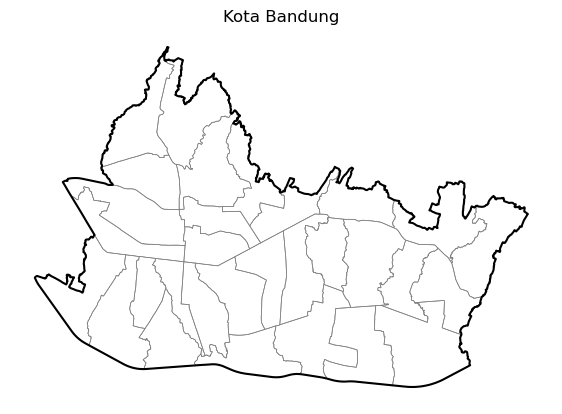

In [12]:
if JALANKAN["batas"]:
    s1_batas.run()
batas = s1_batas.load()
kec = s1_batas.load_kecamatan()
ax = batas.boundary.plot(color="black", figsize=(7, 6))
if kec is not None:
    kec.plot(ax=ax, facecolor="none", edgecolor="grey", linewidth=0.5)
    print(f"{len(kec)} kecamatan (seharusnya 30)")
ax.set_title("Kota Bandung"); ax.set_axis_off()

### 2. POI coffee shop dari OpenStreetMap

In [14]:
if JALANKAN["osm"]:
    s2_osm.run(OSM_SOURCE)
osm = s2_osm.load()
print("snapshot OSM:", osm.snapshot_osm.iat[0])
display(pd.Series({
    "total di Kota Bandung": len(osm),
    "duplikat dibuang": osm.dup_dibuang.sum(),
    "tanpa nama": (osm["name"] == "").sum(),
}, name="jumlah").to_frame())

[2] OSM (overpass): 535 objek, 473 di dalam Kota Bandung, 14 duplikat. snapshot 2026-10-29T17:28:51Z
    kategori: {'kopi_utama': 237, 'osm_cafe': 160, 'teashop': 21, 'non_kopi': 16, 'bubbletea': 12, 'kopi_hybrid': 8, 'donut_bakery': 5}
snapshot OSM: 2026-10-29 17:28:51+00:00


,jumlah
total di Kota Bandung,473
duplikat dibuang,14
tanpa nama,8


In [15]:
o = osm[~osm.dup_dibuang]
display(o.kategori_osm.value_counts().rename("kategori OSM").to_frame())
display(o[o.kategori_osm.isin(["teashop", "bubbletea", "donut_bakery"])]
        .groupby("kategori_osm")["name"].agg(lambda s: ", ".join(s.value_counts().index[:6])).to_frame("contoh"))
o.explore(column="kategori_osm", tooltip=["name", "cuisine", "kategori_osm", "osm_key"], tiles="OpenStreetMap")

,kategori OSM
kategori_osm,
kopi_utama,237
osm_cafe,160
teashop,21
non_kopi,16
bubbletea,12
kopi_hybrid,8
donut_bakery,5


,contoh
kategori_osm,
bubbletea,"Mixue, MIXUE Ciumbuleuit, Xiboba, Susu Mbok Darmi, MIXUE..."
donut_bakery,"J.Co, Dunkin Donuts, J.CO Donuts & Coffee, Clie Banana &..."
teashop,"Chatime, Xing Fu Tang, KOI The, Es Teh Indonesia, Es Teh..."


### 3. Data Open Data (Disbudpar) — bersihkan & klasifikasikan

[3] Pemkot: 9121 baris mentah -> 1281 tempat unik ({'kopi_utama': 779, 'cafe_ambigu': 246, 'kopi_hybrid': 100, 'non_kopi': 83, 'donut_bakery': 38, 'teashop': 30, 'bubbletea': 5})


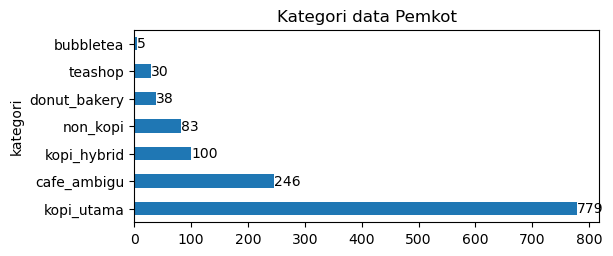

In [16]:
if JALANKAN["pemkot"]:
    s3_pemkot.run()
pk = s3_pemkot.load()
ax = pk.kategori.value_counts().plot.barh(figsize=(6, 2.5), title="Kategori data Pemkot")
for c in ax.containers: ax.bar_label(c)

In [17]:
# contoh acak per kategori, untuk mengecek apakah aturan di config.py sudah tepat
display(pd.concat([g.sample(min(5, len(g)), random_state=1) for _, g in pk.groupby("kategori")])
          [["kategori", "nama", "alamat_lengkap"]])

,kategori,nama,alamat_lengkap
520,bubbletea,"ITAKOYAKI, CORNDOG, SOSTEL DAN BOBA",JL. RAJAWALI TIMUR NO.29
347,bubbletea,DR BOBA DRINK'S,JL. BABAKAN CIANJUR NO.8
854,bubbletea,MOMOYO GEGERKALONG,JL. GEGERKALONG HILIR NO.55
299,bubbletea,DAPOER CHERRY BOBA N CORN DOG TOPOKKY,MESJID HIDAYATUL NURUL IMAN JL.CIPOREAT KP.MANDALAWANGI ...
846,bubbletea,MIXUE,JL. SURYA SUMANTRI NO. 72B
183,cafe_ambigu,CAFE LEMBANNA BANDUNG,"JL. BELITUNG NO.20, MERDEKA, KEC. SUMUR BANDUNG, KOTA BA..."
1277,cafe_ambigu,ZIE CAFE,"JL. VAN DEVENTER NO.14, KB. PISANG, KEC. SUMUR BANDUNG, ..."
1051,cafe_ambigu,SAGA CAFE & MART,JL. LOMBOK NO.8
1154,cafe_ambigu,SWISS CAFE,JL. KEBON KAWUNG NO.1A
314,cafe_ambigu,DEN'S CAFE,JL. A.H. NASUTION NO.116


In [18]:
s4_geocode.run(hitung_ulang=True)

[4] geocode: 1281 tempat | 0 sudah | 0 koreksi manual | 1281 diproses sekarang
   20/1281  (0 request baru)
   40/1281  (0 request baru)
   60/1281  (0 request baru)
   80/1281  (0 request baru)
   100/1281  (0 request baru)
   120/1281  (0 request baru)
   140/1281  (0 request baru)
   160/1281  (0 request baru)
   180/1281  (0 request baru)
   200/1281  (0 request baru)
   220/1281  (0 request baru)
   240/1281  (0 request baru)
   260/1281  (0 request baru)
   280/1281  (0 request baru)
   300/1281  (0 request baru)
   320/1281  (0 request baru)
   340/1281  (0 request baru)
   360/1281  (0 request baru)
   380/1281  (0 request baru)
   400/1281  (0 request baru)
   420/1281  (0 request baru)
   440/1281  (0 request baru)
   460/1281  (0 request baru)
   480/1281  (0 request baru)
   500/1281  (0 request baru)
   520/1281  (0 request baru)
   540/1281  (0 request baru)
   560/1281  (0 request baru)
   580/1281  (0 request baru)
   600/1281  (0 request baru)
   620/1281  (0 request b

### 4. Geocoding alamat Pemkot

Hasil tersimpan di cache. Kalau sel ini di-*interrupt* (tombol ■), progres **tidak hilang**. Jalankan ulang sel untuk melanjutkan.

[4] geocode: 1281 tempat | 1281 sudah | 0 koreksi manual | 0 diproses sekarang
[4] presisi: {'poi_dekat_alamat': 103, 'poi': 26, 'bangunan': 359, 'gedung': 16, 'jalan_pendek': 329, 'jalan': 199, 'kelurahan': 57, 'kecamatan': 6, 'gagal': 186}
    sudah diproses 1281/1281; layak dipakai 833/1281 (65%)
    379 tempat perlu dicek manual -> data/final/perlu_review_koordinat.csv


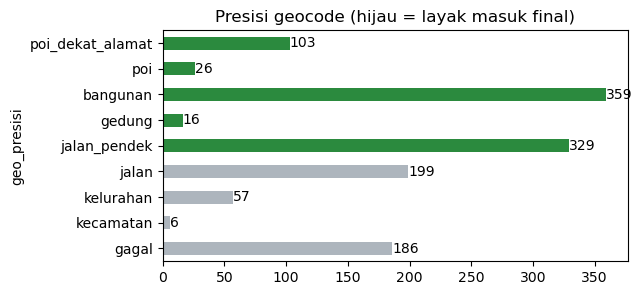

In [19]:
if JALANKAN["geocode"]:
    s4_geocode.run(limit=GEOCODE_LIMIT)
geo = s4_geocode.load()
urut = [p for p in C.PRESISI_URUT + ["gagal", "belum"] if p in set(geo.geo_presisi)]
vc = geo.geo_presisi.value_counts().reindex(urut)
ax = vc.plot.barh(figsize=(6, 3), color=["#2b8a3e" if p in C.GEOCODE_PRESISI_OK else "#adb5bd" for p in vc.index],
                  title="Presisi geocode (hijau = layak masuk final)")
ax.invert_yaxis()
for c in ax.containers: ax.bar_label(c)

In [20]:
# perkiraan ketidakpastian posisi (meter) per presisi
display(pd.to_numeric(geo.geo_ketidakpastian_m, errors="coerce").groupby(geo.geo_presisi)
          .describe()[["count", "50%", "max"]].round(0))
# kandidat yang ditolak validator & alasannya
tolak = geo[geo.geo_ditolak.astype(str) != ""].geo_ditolak.str.split(";").explode()
display(tolak.str.split(":").str[1].value_counts().rename("alasan ditolak").to_frame())
display(geo[geo.geo_presisi.isin(C.GEOCODE_PRESISI_OK)]
        [["nama", "jalan", "geo_presisi", "geo_metode", "geo_label"]].head(10))

,count,50%,max
geo_presisi,,,
bangunan,359.0,25.0,25.0
gagal,0.0,NaN,NaN
gedung,16.0,232.0,232.0
jalan,199.0,210.0,1015.0
jalan_pendek,329.0,76.0,150.0
kecamatan,6.0,2700.0,2700.0
kelurahan,57.0,1022.0,2842.0
poi,26.0,16.0,25.0
poi_dekat_alamat,103.0,8.0,25.0


,alasan ditolak
geo_ditolak,
beda_kecamatan,50
di_luar_kota,49
jauh_dari_alamat,28
beda_jalan,12
ambigu_3_lokasi,8
ambigu_2_lokasi,8
ambigu_5_lokasi,4
ambigu_4_lokasi,1


,nama,jalan,geo_presisi,geo_metode,geo_label
0,#KUY CAFE,JL. CIKUTRA NO.168 D,bangunan,alamat_photon,"Sekolah Menengah Pertama Negeri 16 Bandung, Jl. PH.H. Mu..."
3,1001 RESTO & COFFEE BY ART FRIENDS BANDUNG,JL. CIHAMPELAS NO.160 AREA) FLOOR LG,bangunan,alamat_nominatim,"Cihampelas Walk (CiWalk), 160, Jalan Cihampelas, Cipagan..."
4,102 CAFE,JL. BOJONG KONENG,jalan_pendek,alamat_nominatim,"Jalan Bojong Koneng, Neglasari, Cibeunying Kaler, Kota B..."
6,150 COFFEE AND GARDEN,JL. SULAKSANA NO.50,poi,nama_kota_nominatim,"150 Coffee and Garden, Jalan Sulaksana, Cicaheum, Kiarac..."
8,18 HRS CAFE,JL. DR. SETIABUDI NO. 103,poi_dekat_alamat,nama_dekat_nominatim,"18 Hrs Cafe, 103, Jalan Dr. Setiabudi, Gegerkalong, Suka..."
9,1933 DAPUR & KOPI,JL. SULANJANA NO.17,jalan_pendek,alamat_nominatim,"Jalan Sulanjana, Pelesiran, Tamansari, Bandung Wetan, Ko..."
12,2 GRAMS COFFEE AND MEALS,JL. AMBON NO.16,bangunan,alamat_photon,"Dinas Kependudukan Dan Pencatatan Sipil Kota Bandung, Ja..."
13,2 TANG CAFE,JL. SUKAJADI BLOK I NO.131-139 SKY LEVEL NO. 6,bangunan,alamat_photon,"Flat Sarijadi Blok I, Jalan Sariwangi, Sarijadi"
15,248 COFFEE,JL. CIBADAK NO.248,bangunan,alamat_photon,"Cibadak Astanaanyar, Jalan Astana Anyar, Karang Anyar"
18,"360 GRILL, PIZZA & COFFEE",JL. SUKAJADI NO.810,gedung,gedung_nominatim,"Paris Van Java, Jalan Sukaresik 2, Cipedes, Sukajadi, Ko..."


### 5. Pencocokan Pemkot ↔ OSM

In [21]:
if JALANKAN["match"]:
    s5_match.run()
mt = s5_match.load()
display(mt.metode.value_counts().rename("pasangan").to_frame())
contoh = mt.merge(geo[["nama"]], left_on="pk_idx", right_index=True) \
           .merge(osm[~osm.dup_dibuang].reset_index(drop=True)[["name"]], left_on="osm_idx", right_index=True)
display(contoh[["nama", "name", "metode", "skor_nama", "jarak_m"]].sort_values("skor_nama").head(10))

[5] match: 103 pasangan ({'spasial': 96, 'nama': 7})


,pasangan
metode,
spasial,96
nama,7


,nama,name,metode,skor_nama,jarak_m
102,GIGGLEBOX CAFE AND RESTO,Giggle Box Cafe And Resto,nama,96.774194,NaN
74,FORE COFFEE,Fore Coffee,spasial,100.000000,0.0
73,FORE COFFEE,Fore Coffee,spasial,100.000000,0.0
72,FORE COFFEE,Fore Coffee,spasial,100.000000,59.8
71,5758 COFFEE LAB,Coffee Lab 5758,spasial,100.000000,5.8
70,ADD+ COFFEE,Warkop ADD,spasial,100.000000,0.0
69,ADIKSI KOPI,Adiksi Kopi,spasial,100.000000,11.0
68,AROMA COFFEE,Kopi Aroma,spasial,100.000000,4.1
67,BADUNG CAFE N RESTO,Badung Cafe & Resto,spasial,100.000000,0.0
66,BAGI KOPI,Bagi Kopi,spasial,100.000000,0.6


### 6. Dataset final

Kategori yang masuk final diatur oleh `KATEGORI_FINAL` di `config.py`.

In [22]:
if JALANKAN["final"]:
    s6_final.run()
meta = json.loads((C.FINAL / "metadata.json").read_text())
final = gpd.read_file(C.FINAL / "coffeeshop_bandung.geojson")
print(f"Dataset final: {len(final)} coffee shop | snapshot OSM {meta['snapshot_osm']}")
display(final.sumber_koordinat.value_counts().rename("sumber koordinat").to_frame())
semua = pd.read_csv(C.FINAL / "coffeeshop_bandung_semua.csv")
display(semua.groupby(["kategori", "sumber"]).size().unstack(fill_value=0)
             .assign(masuk_final=lambda t: t.index.isin(C.KATEGORI_FINAL)))

    dedup: 66 duplikat dibuang, 218 titik perlu dicek (alamat/koordinat sama, nama beda)
[6] final: 695 coffee shop -> data/final/coffeeshop_bandung.(csv|geojson)
{
  "total_kandidat": 1637,
  "final": 695,
  "duplikat_dibuang": 66,
  "cek_manual": 218,
  "per_sumber_final": {
    "pemkot": 447,
    "osm": 163,
    "pemkot+osm": 85
  },
  "per_kategori_semua": {
    "kopi_utama": 945,
    "cafe_ambigu": 242,
    "osm_cafe": 144,
    "kopi_hybrid": 107,
    "non_kopi": 95,
    "teashop": 46,
    "donut_bakery": 41,
    "bubbletea": 17
  },
  "sumber_koordinat_semua": {
    "osm": 459,
    "geocode_bangunan": 349,
    "geocode_jalan_pendek": 326,
    "tanpa_koordinat(jalan)": 195,
    "tanpa_koordinat(gagal)": 186,
    "tanpa_koordinat(kelurahan)": 57,
    "geocode_poi_dekat_alamat": 41,
    "geocode_gedung": 10,
    "geocode_poi": 8,
    "tanpa_koordinat(kecamatan)": 6
  }
}
Dataset final: 695 coffee shop | snapshot OSM 2026-10-29 17:28:51+00:00


,sumber koordinat
sumber_koordinat,
osm,248
geocode_jalan_pendek,231
geocode_bangunan,204
geocode_gedung,6
geocode_poi,3
geocode_poi_dekat_alamat,3


sumber,osm,pemkot,pemkot+osm,masuk_final
kategori,,,,
bubbletea,12,5,0,False
cafe_ambigu,0,235,7,False
donut_bakery,3,36,2,False
kopi_hybrid,7,99,1,True
kopi_utama,162,699,84,True
non_kopi,12,78,5,False
osm_cafe,144,0,0,False
teashop,16,26,4,False


In [23]:
final.explore(column="sumber_koordinat", tooltip=["nama", "alamat", "kategori", "sumber_koordinat"],
              tiles="OpenStreetMap", style_kwds={"radius": 4})

kecamatan,Bandung Wetan,Coblong,Sumur Bandung,Lengkong,Sukajadi,Cidadap,Cibeunying Kaler,Batununggal,Cicendo,Gedebage,...,Cibiru,Buahbatu,Babakan Ciparay,Panyileukan,Bandung Kidul,Bandung Kulon,Rancasari,Mandalajati,Ujungberung,Arcamanik
jumlah,128,98,84,63,40,32,26,23,21,20,...,8,7,6,6,5,5,4,3,2,1


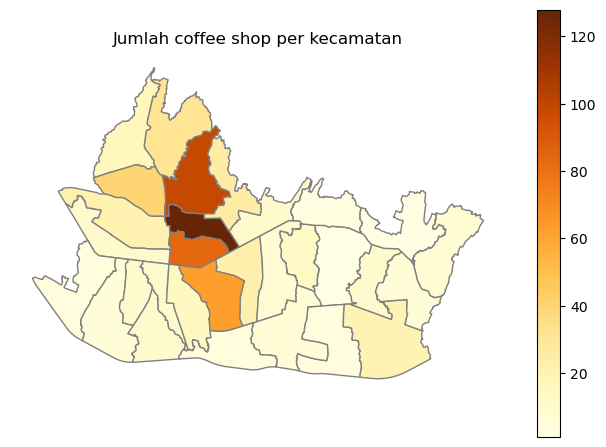

In [24]:
# sebaran per kecamatan: cek bias spasial (mis. Bandung utara kosong = data terpotong)
if kec is not None:
    per_kec = gpd.sjoin(final, kec[["kecamatan", "geometry"]], predicate="within").kecamatan.value_counts()
    kk = kec.set_index("kecamatan").assign(n=per_kec).fillna({"n": 0})
    ax = kk.plot(column="n", cmap="YlOrBr", legend=True, edgecolor="grey", figsize=(8, 6))
    ax.set_title("Jumlah coffee shop per kecamatan"); ax.set_axis_off()
    display(per_kec.rename("jumlah").to_frame().T)

### 7. Validasi manual

- `sampel_validasi.csv`: isi kolom `label_manual`, lalu hitung akurasi klasifikasi per kategori.
- `perlu_review_koordinat.csv`: isi `lat`/`lon` yang benar, salin ke `data/raw/koreksi_koordinat.csv`, lalu jalankan ulang langkah 4 sampai 6.

In [25]:
s6_final.sampel()
s4_geocode.review()

[v] 227 baris -> sampel_validasi.csv. Label: coffee_shop / bukan, lalu hitung akurasi per kategori.
    379 tempat perlu dicek manual -> data/final/perlu_review_koordinat.csv


In [26]:
# setelah sampel_validasi.csv dilabeli (label_manual = coffee_shop / bukan):
sv = pd.read_csv(C.FINAL / "sampel_validasi.csv", keep_default_na=False)
if (sv.label_manual != "").any():
    sv = sv[sv.label_manual != ""]
    display(sv.groupby("kategori").label_manual.apply(lambda s: (s == "coffee_shop").mean())
              .rename("proporsi benar coffee shop").to_frame())
else:
    print("Belum ada label_manual yang diisi.")

Belum ada label_manual yang diisi.
